# Exploración, Limpieza y Partición (Bank Marketing)
**Grupo:** Grupo 4  
**Archivo del módulo:** `src/datos.py`  
**Objetivo del notebook:** Ejecutar y validar el pipeline modularizado de preprocesamiento, asegurando el aislamiento estricto de datos (sin fuga de información), codificación adecuada, estratificación y gráficos limpios de las particiones.

In [1]:
import sys
from pathlib import Path

# Añadir la raíz del proyecto para importar desde src
sys.path.append(str(Path().resolve().parent))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
print("Entorno cargado correctamente.")

Entorno cargado correctamente.


## Configuración del Entorno de Trabajo e Importación de Librerías

En esta sección inicializamos las librerías fundamentales para la manipulación de datos (`pandas`, `numpy`) y la generación de gráficos estadísticos (`matplotlib`, `seaborn`). Asimismo, configuramos dinámicamente el `sys.path` para garantizar la importación limpia y modular de los scripts personalizados ubicados en la carpeta `src/`.

In [2]:
from pathlib import Path
from src.datos import cargar_y_limpiar_datos

# Detectar automáticamente la ruta correcta del archivo según el entorno
if Path("data/bank-full.csv").exists():
    ruta_csv = "data/bank-full.csv"
elif Path("../data/bank-full.csv").exists():
    ruta_csv = "../data/bank-full.csv"
else:
    ruta_csv = "./data/bank-full.csv"

# Cargar y limpiar el dataset usando la variable dinámicamente
X, y = cargar_y_limpiar_datos(ruta_csv)

print("Dimensiones de X (características):", X.shape)
print("Dimensiones de y (objetivo):", y.shape)

Dimensiones de X (características): (45195, 15)
Dimensiones de y (objetivo): (45195,)


## Carga y Limpieza del Dataset (Bank Marketing)

Importamos la función modular `cargar_y_limpiar_datos` desde el directorio `src/` para procesar el archivo CSV original. Esta función se encarga de:
1. Leer el archivo estructurado utilizando el separador adecuado (`;`).
2. Eliminar la columna `duration` para **prevenir la fuga de datos** (*data leakage*).
3. Eliminar las filas duplicadas que aparecen al quitar `duration` (un mismo cliente no debe quedar en entrenamiento y en prueba).
4. Codificar la variable objetivo `y` en formato binario (`0` y `1`).

La codificación *One-Hot* ya no se hace en este paso: la realiza el preprocesador de `src/modelo.py`, ajustado solo con entrenamiento.

In [3]:
import warnings
warnings.filterwarnings('ignore', category=FutureWarning)
from src.datos import preparar_particiones

# Particionar en 70% Train, 15% Val y 15% Test
X_train, X_val, X_test, y_train, y_val, y_test = preparar_particiones(X, y)

print("Particiones generadas correctamente:")
print(f"Entrenamiento: {X_train.shape}")
print(f"Validación:    {X_val.shape}")
print(f"Prueba:        {X_test.shape}")

Particiones generadas correctamente:
Entrenamiento: (31638, 15)
Validación:    (6777, 15)
Prueba:        (6780, 15)


## Generación de Particiones

Ejecutamos la función modular `preparar_particiones` para dividir el conjunto de datos respetando las proporciones de **70% para entrenamiento**, **15% para validación** y **15% para prueba**, aplicando además **estratificación** para mantener intacto el desbalance de clases original. 

Las particiones se guardan **sin escalar**. El preprocesamiento (One-Hot y, si hubiera variables numéricas, `StandardScaler`) se ajusta después **estrictamente sobre el conjunto de entrenamiento** para evitar cualquier fuga de información (*data leakage*) hacia los conjuntos de validación y prueba.

In [4]:
conteo_clases = y_train.value_counts()
proporcion_clases = (y_train.value_counts(normalize=True) * 100).round(2)

df_balance = pd.DataFrame({'Conteo': conteo_clases, 'Porcentaje (%)': proporcion_clases})
print("Distribución de la variable objetivo en entrenamiento:")
print(df_balance)

Distribución de la variable objetivo en entrenamiento:
   Conteo  Porcentaje (%)
y                        
0   27935            88.3
1    3703            11.7


## Análisis del Desbalance de Clases en el Conjunto de Entrenamiento

Calculamos el conteo absoluto y porcentual de la variable objetivo (`y_train`) para verificar cuantitativamente el desbalance de clases. Esto resulta fundamental antes de entrenar los modelos predictivos, ya que permite decidir si se requerirán técnicas adicionales de ponderación o manejo de clases desbalanceadas.

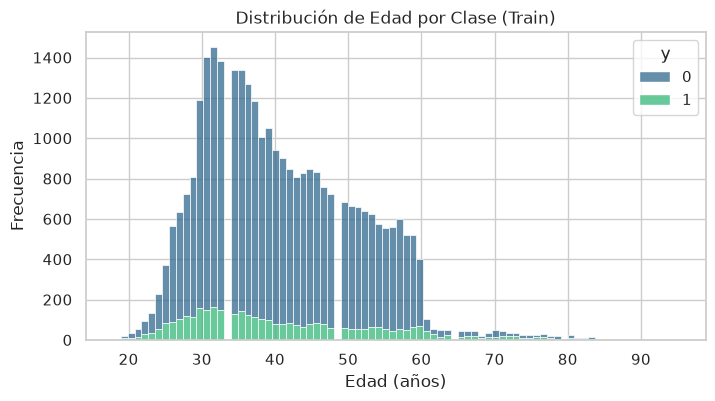

In [5]:
plt.figure(figsize=(8, 4))
sns.histplot(data=X_train, x="age", hue=y_train, multiple="stack", palette="viridis")
plt.title("Distribución de Edad por Clase (Train)")
plt.xlabel("Edad (años)")
plt.ylabel("Frecuencia")
plt.show()

## Análisis de Distribución de Edad según la Variable Objetivo

Generamos un histograma apilado (*stacked histogram*) para analizar la distribución de la variable `age` en el conjunto de entrenamiento, diferenciada por las clases de la variable objetivo (`y_train`). Esto nos permite identificar patrones etarios o diferencias en el comportamiento de aceptación frente a la campaña de marketing según los rangos de edad.

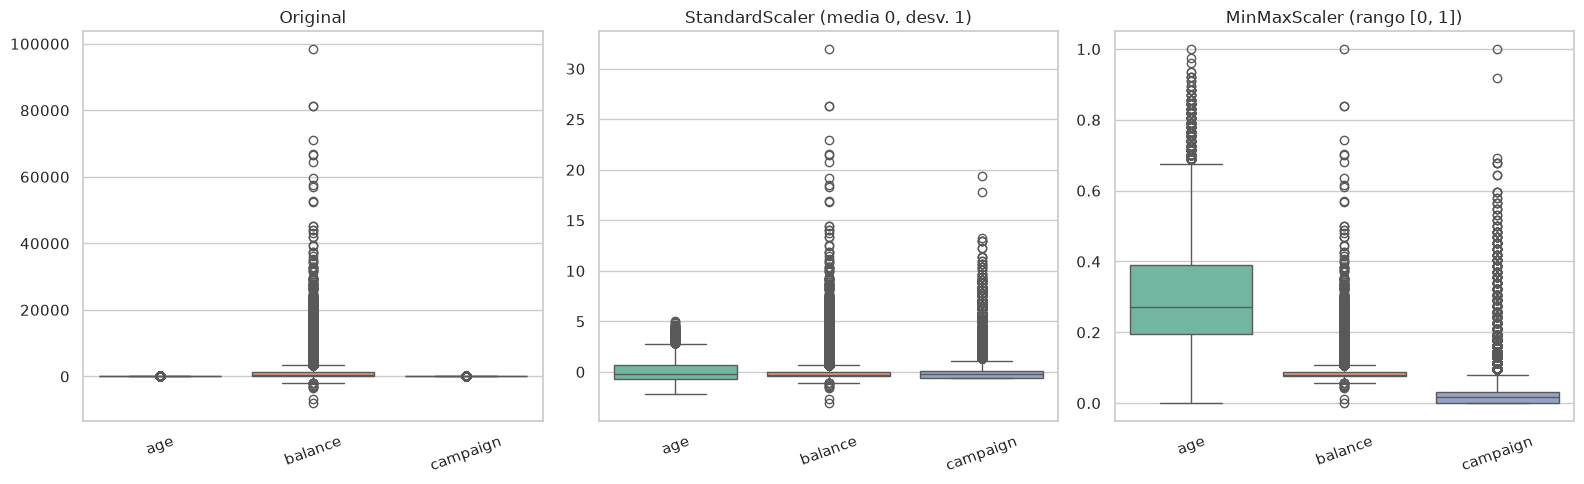

In [6]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler

# Definimos las columnas numéricas de ejemplo para el gráfico
cols_ejemplo = ['age', 'balance', 'campaign']

# 1. Escalado con StandardScaler (media 0, desviación estándar 1)
scaler_standard = StandardScaler()
X_train_scaled = X_train.copy()
X_train_scaled[cols_ejemplo] = scaler_standard.fit_transform(X_train[cols_ejemplo])

# 2. Escalado con MinMaxScaler (rango entre 0 y 1)
scaler_minmax = MinMaxScaler()
X_train_minmax = X_train.copy()
X_train_minmax[cols_ejemplo] = scaler_minmax.fit_transform(X_train[cols_ejemplo])

# Creamos la figura con 1 fila y 3 columnas de subplots
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# 1. Panel Izquierdo: Datos Originales
sns.boxplot(data=X_train[cols_ejemplo], ax=axes[0], palette="Set2")
axes[0].set_title("Original")
axes[0].tick_params(axis='x', rotation=20)

# 2. Panel Central: StandardScaler
sns.boxplot(data=X_train_scaled[cols_ejemplo], ax=axes[1], palette="Set2")
axes[1].set_title("StandardScaler (media 0, desv. 1)")
axes[1].tick_params(axis='x', rotation=20)

# 3. Panel Derecho: MinMaxScaler
sns.boxplot(data=X_train_minmax[cols_ejemplo], ax=axes[2], palette="Set2")
axes[2].set_title("MinMaxScaler (rango [0, 1])")
axes[2].tick_params(axis='x', rotation=20)

plt.tight_layout()
plt.show()

## Escalado Numérico Seguro (Evitando Data Leakage)
Se compara `StandardScaler` sobre variables numéricas clave (`age`, `balance`, `campaign`). Como el modelo final usa solo variables categóricas (ver la selección de variables al final), el escalado no se aplica en el entrenamiento, pero el preprocesador de `src/modelo.py` lo haría con la misma regla si se agregara una variable numérica.

* **Regla estricta aplicada:** El ajuste (`fit_transform`) se realizó **exclusivamente con el conjunto de entrenamiento**, y los conjuntos de validación y prueba solo se transformaron (`transform`), evitando cualquier tipo de contaminación de datos futuros.

In [7]:
cols_numericas = ['age', 'balance', 'day', 'campaign', 'pdays', 'previous']
df_corr = X_train[cols_numericas].copy()
df_corr['y'] = y_train.values

matriz_corr = df_corr.corr()
print("Correlaciones de variables numéricas respecto a la variable objetivo (y):")
print(matriz_corr['y'].sort_values(ascending=False))

Correlaciones de variables numéricas respecto a la variable objetivo (y):
y           1.000000
pdays       0.101028
previous    0.093077
balance     0.058944
age         0.023216
day        -0.025615
campaign   -0.072274
Name: y, dtype: float64


## Análisis de Correlación de Variables Numéricas con la Variable Objetivo

Calculamos la matriz de correlación lineal para las principales variables numéricas del conjunto de entrenamiento (`age`, `balance`, `day`, `campaign`, `pdays`, `previous`), incorporando la variable objetivo (`y`). Posteriormente, ordenamos los coeficientes de correlación de forma descendente respecto a `y` para identificar cuáles características guardan mayor relación lineal con la aceptación del producto financiero.

In [8]:
print(f"Total de columnas del conjunto de entrenamiento (antes de One-Hot): {X_train.shape[1]}")
print("\nPrimeras 5 filas del conjunto de entrenamiento:")
X_train.head()

Total de columnas del conjunto de entrenamiento (antes de One-Hot): 15

Primeras 5 filas del conjunto de entrenamiento:


,age,job,marital,education,default,balance,housing,loan,contact,day,month,campaign,pdays,previous,poutcome
27979,43,blue-collar,married,secondary,no,1035,no,no,cellular,28,jan,1,-1,0,unknown
39554,54,unknown,married,secondary,no,1157,no,no,cellular,26,may,2,-1,0,unknown
38411,36,admin.,married,secondary,no,1479,no,no,cellular,15,may,2,-1,0,unknown
27325,57,technician,married,secondary,no,7766,yes,no,cellular,21,nov,1,-1,0,unknown
4983,31,admin.,single,tertiary,no,1583,yes,no,unknown,21,may,1,-1,0,unknown


## Verificación de Dimensionalidad y Muestra de Datos

Imprimimos el número total de columnas (antes de la codificación *One-Hot*) y mostramos las primeras 5 filas del conjunto de entrenamiento (`X_train`) para verificar visualmente la estructura y correcta transformación de los datos antes del modelado.

In [9]:
from pathlib import Path

# Guardar en la misma carpeta data/ donde está bank-full.csv (funciona desde la raíz o desde notebooks/)
carpeta_data = Path(ruta_csv).parent

# Guardar los archivos (sin escalar) utilizando la ruta correcta
X_train.to_csv(carpeta_data / "X_train.csv", index=False)
X_val.to_csv(carpeta_data / "X_val.csv", index=False)
X_test.to_csv(carpeta_data / "X_test.csv", index=False)
y_train.to_csv(carpeta_data / "y_train.csv", index=False)
y_val.to_csv(carpeta_data / "y_val.csv", index=False)
y_test.to_csv(carpeta_data / "y_test.csv", index=False)

print("¡Etapa 2 finalizada exitosamente! Archivos guardados en la carpeta 'data/'.")

¡Etapa 2 finalizada exitosamente! Archivos guardados en la carpeta 'data/'.


## Comparación de Métodos de Escalado (StandardScaler vs. MinMaxScaler)

Para determinar el impacto de la normalización sobre las variables numéricas continuas y discretas (`age`, `balance`, `campaign`), comparamos la distribución original frente a dos enfoques de escalado:

1. **StandardScaler:** Transforma los datos para que tengan una media igual a $0$ y una desviación estándar igual a $1$. Es la opción idónea para algoritmos basados en distancias (como KNN o Regresión Logística) ya que conserva las relaciones de varianza sin distorsionar la presencia de valores atípicos (*outliers*).
2. **MinMaxScaler:** Acota los valores en un rango estricto entre $0$ y $1$. Es útil cuando se requiere un límite acotado, aunque puede comprimir la mayoría de los datos en un rango muy estrecho si existen valores atípicos extremos.

> **Nota de seguridad:** Ambas transformaciones se ajustaron (*fit*) **exclusivamente con el conjunto de entrenamiento (`X_train`)** para evitar la fuga de información (*data leakage*) hacia los conjuntos de validación y prueba.

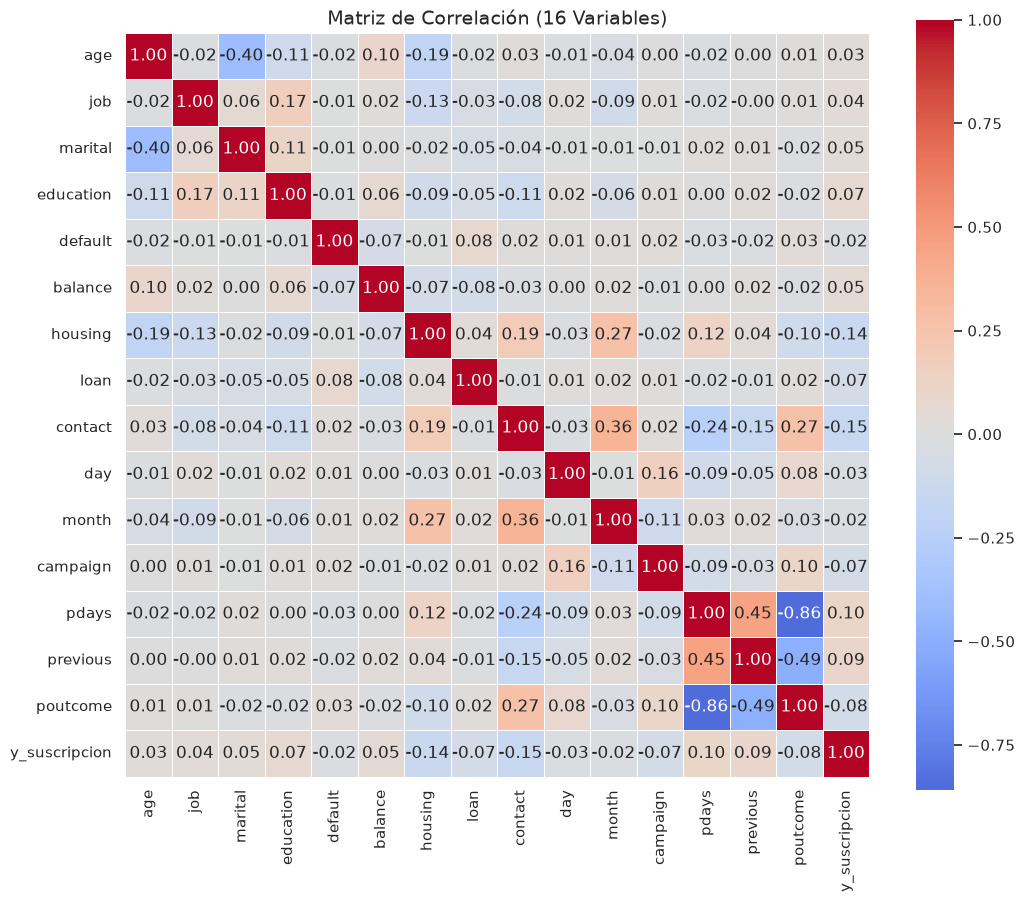

In [10]:
# --- Celda Aparte: Matriz de Correlación ---
from sklearn.preprocessing import OrdinalEncoder

# 1. Cargar datos directamente para conservar las 16 variables
df_raw = pd.read_csv(ruta_csv, sep=";")
df_16 = df_raw.drop(columns=['duration']).copy()

# 2. Codificar variables categóricas
cat_cols = df_16.select_dtypes(include=['object', 'str']).columns
encoder = OrdinalEncoder()
df_encoded = df_16.copy()
df_encoded[cat_cols] = encoder.fit_transform(df_16[cat_cols])
df_encoded = df_encoded.rename(columns={'y': 'y_suscripcion'})

# 3. Calcular y graficar la matriz de correlación
plt.figure(figsize=(12, 10))
sns.heatmap(
    df_encoded.corr(), 
    annot=True, 
    fmt=".2f", 
    cmap="coolwarm", 
    center=0, 
    square=True, 
    linewidths=0.5
)
plt.title("Matriz de Correlación (16 Variables)", fontsize=14)
plt.show()

In [11]:
from src.datos import ranking_correlacion, VARIABLES_SELECCIONADAS

# Ranking de asociación con y, calculado solo con entrenamiento:
# Pearson |r| para numéricas y V de Cramér para categóricas.
ranking = ranking_correlacion(X_train, y_train)

# Puesto que tendría cada variable si las categorías se codificaran como 0, 1, 2... (OrdinalEncoder)
df_cod = X_train.copy()
df_cod[cat_cols.drop('y')] = OrdinalEncoder().fit_transform(df_cod[cat_cols.drop('y')])
puesto_codificado = df_cod.corrwith(y_train).abs().rank(ascending=False).astype(int)
ranking["puesto_con_OrdinalEncoder"] = ranking["variable"].map(puesto_codificado)
ranking

,variable,medida,asociacion,puesto_con_OrdinalEncoder
1,poutcome,V de Cramer,0.3178,5
2,month,V de Cramer,0.2577,12
3,contact,V de Cramer,0.1513,1
4,housing,V de Cramer,0.1433,2
5,job,V de Cramer,0.1374,11
6,pdays,Pearson |r|,0.1010,3
7,previous,Pearson |r|,0.0931,4
8,education,V de Cramer,0.0739,7
9,marital,V de Cramer,0.0727,10
10,campaign,Pearson |r|,0.0723,6


## Selección de Variables mediante el Ranking de Correlación

La matriz anterior codifica las categorías como números (0, 1, 2...) con `OrdinalEncoder`. Eso introduce un orden que no existe: por ejemplo, los meses quedan en orden alfabético y la correlación de Pearson los trata como si "dec" fuera mayor que "apr". Por eso, para medir la relación de cada variable con `y` se usó:

* **Variables numéricas:** valor absoluto de la correlación de Pearson.
* **Variables categóricas:** **V de Cramér**, que mide la asociación entre categorías sin suponer un orden (0 = ninguna relación, 1 = relación total).

Todo se calculó **solo con el conjunto de entrenamiento**. Con este método, `month` pasa del puesto 12 al 2.

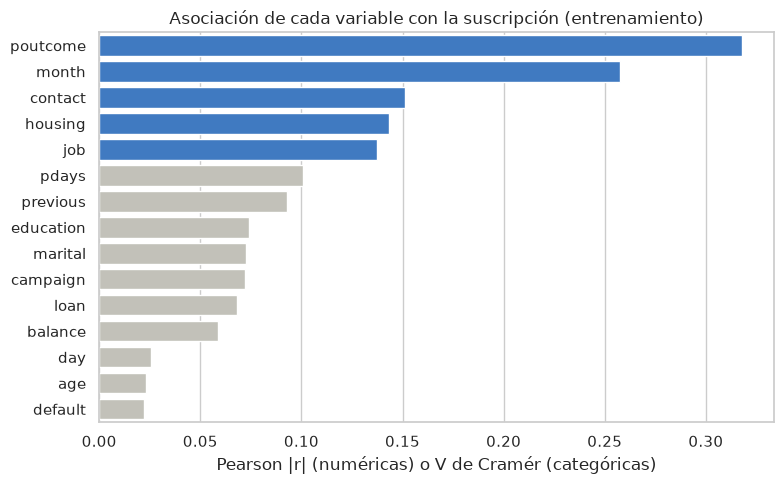

Tasa de suscripción por mes (entrenamiento):
month
may    0.066
jul    0.091
nov    0.102
jun    0.103
jan    0.108
aug    0.112
feb    0.167
apr    0.193
oct    0.429
dec    0.457
sep    0.475
mar    0.506


In [12]:
plt.figure(figsize=(8, 5))
colores = ["#2a78d6" if v in VARIABLES_SELECCIONADAS else "#c3c2b7" for v in ranking["variable"]]
sns.barplot(data=ranking, y="variable", x="asociacion", hue="variable", palette=colores, legend=False)
plt.title("Asociación de cada variable con la suscripción (entrenamiento)")
plt.xlabel("Pearson |r| (numéricas) o V de Cramér (categóricas)")
plt.ylabel("")
plt.tight_layout()
plt.show()

print("Tasa de suscripción por mes (entrenamiento):")
print(y_train.groupby(X_train["month"]).mean().sort_values().round(3).to_string())

## Variables Elegidas para el Modelo

Se eligieron las **5 variables con mayor asociación**: `poutcome`, `month`, `contact`, `housing` y `job` (en azul en el gráfico). La tasa de suscripción por mes confirma el resultado: va de alrededor de 7% en mayo a más de 50% en marzo.

* El modelo, la API y el chatbot usan exactamente estas 5 variables, por lo que el chatbot no necesita completar datos con valores supuestos.
* Solo una de ellas (`job`) es una variable demográfica; en la Etapa 4 se revisa si el error del modelo cambia entre ocupaciones.
* Las variables restantes tienen una asociación mucho menor con `y`.